# 03 — Avaliação e análise dos modelos base

Usa os resultados do `02_treino.ipynb` (pasta `MyDrive/leafscan/runs/`) e gera as tabelas e figuras do artigo.
Não treina nada; só o Grad-CAM usa a GPU (alguns segundos).

| Seção | Saída |
|---|---|
| Tabela de resultados | `results/tables/tab_base.csv` e `.tex` |
| Curvas de treino | `results/figs/curvas_treino.png` |
| Acurácia por cultura × por doença | `results/tables/tab_cultura.csv` |
| Matrizes de confusão | `results/figs/cm_pv_<run>.png`, `cm_pd_<run>.png` |
| F1 por classe no PlantDoc | `results/tables/f1_classe_pd.csv`, `results/figs/f1_classe_pd.png` |
| Confiança × acurácia (limiar do app) | `results/tables/limiar.csv`, `results/figs/confianca.png` |
| Grad-CAM | `results/figs/gradcam_<run>.png` |

## 1. Configuração e dados

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score

DRIVE_DIR = '/content/drive/MyDrive/leafscan'
CACHE_DIR = f'{DRIVE_DIR}/cache'
RUNS_DIR  = f'{DRIVE_DIR}/runs'
FIG_DIR   = f'{DRIVE_DIR}/results/figs'
TAB_DIR   = f'{DRIVE_DIR}/results/tables'
for d in (FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)

meta = json.load(open(f'{CACHE_DIR}/meta.json'))
PV_CLASSES = meta['pv_classes']
PD_IDX = np.array(meta['pd_pv_indices'])
SEED = meta['seed']

def short(c):
    crop, _, dis = c.partition('___')
    crop = crop.split('_(')[0].replace(',_bell', ' (pepper)').replace('_', ' ')
    return f"{crop} - {dis.replace('_', ' ').strip()}"
SHORT = [short(c) for c in PV_CLASSES]
CROP = np.array([c.split('___')[0] for c in PV_CLASSES])

pv_y = np.load(f'{CACHE_DIR}/pv_y.npy').astype(int); pv_split = np.load(f'{CACHE_DIR}/pv_split.npy')
pd_y = np.load(f'{CACHE_DIR}/pd_y.npy').astype(int); pd_split = np.load(f'{CACHE_DIR}/pd_split.npy')
y_te = pv_y[pv_split == 2]
y_pd = pd_y[pd_split == 2]

RUNS = [r for r in ('cnn_base', 'mnv3s', 'mnv2_050') if os.path.exists(f'{RUNS_DIR}/{r}/metrics.json')]
P_PV = {r: np.load(f'{RUNS_DIR}/{r}/pred_pv_test.npy').astype(np.float32) for r in RUNS}
P_PD = {r: np.load(f'{RUNS_DIR}/{r}/pred_pd_test.npy').astype(np.float32) for r in RUNS}
print('Runs encontrados:', RUNS)
assert all(len(P_PV[r]) == len(y_te) and len(P_PD[r]) == len(y_pd) for r in RUNS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Runs encontrados: ['cnn_base', 'mnv3s', 'mnv2_050']


## 2. Tabela principal

In [2]:
NAMES = {'cnn_base': 'CNN própria', 'mnv3s': 'MobileNetV3-Small', 'mnv2_050': 'MobileNetV2 (α=0.5)'}
rows = [json.load(open(f'{RUNS_DIR}/{r}/metrics.json')) for r in RUNS]
tab = pd.DataFrame(rows).set_index('run')
tab.insert(0, 'modelo', [NAMES[r] for r in tab.index])
tab['queda_pp'] = 100 * (tab['pv_test_acc'] - tab['pd_acc_38'])
tab.to_csv(f'{TAB_DIR}/tab_base.csv')

tex = tab[['modelo', 'params', 'train_time_min', 'pv_test_acc', 'pv_test_f1', 'pd_acc_38', 'pd_f1_38', 'pd_acc_restrito']].copy()
for c in ['pv_test_acc', 'pv_test_f1', 'pd_acc_38', 'pd_f1_38', 'pd_acc_restrito']:
    tex[c] = (100 * tex[c]).round(1)
tex['params'] = (tex['params'] / 1e6).round(2)
tex['train_time_min'] = tex['train_time_min'].round(1)
tex.columns = ['Modelo', 'Parâm. (M)', 'Treino (min)', 'Acc PV', 'F1 PV', 'Acc PD', 'F1 PD', 'Acc PD (restr.)']
tex.to_latex(f'{TAB_DIR}/tab_base.tex', index=False, float_format='%.1f')
BEST = tab['pd_acc_38'].idxmax()
print('Melhor modelo no PlantDoc:', BEST)
tex

Melhor modelo no PlantDoc: cnn_base


,Modelo,Parâm. (M),Treino (min),Acc PV,F1 PV,Acc PD,F1 PD,Acc PD (restr.)
run,,,,,,,,
cnn_base,CNN própria,1.18,14.5,99.3,99.2,13.1,11.2,14.4
mnv3s,MobileNetV3-Small,0.96,5.9,98.3,98.0,8.9,6.4,9.7
mnv2_050,MobileNetV2 (α=0.5),0.75,7.6,97.8,97.1,7.6,7.0,11.4


## 3. Curvas de treino

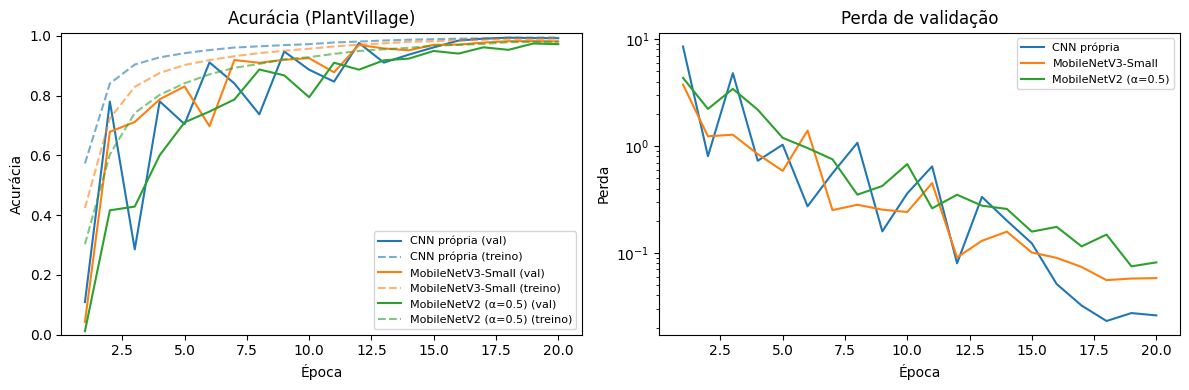

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for r in RUNS:
    h = pd.read_csv(f'{RUNS_DIR}/{r}/history.csv')
    l, = ax[0].plot(h['epoch'] + 1, h['val_accuracy'], label=f'{NAMES[r]} (val)')
    ax[0].plot(h['epoch'] + 1, h['accuracy'], '--', color=l.get_color(), alpha=0.6, label=f'{NAMES[r]} (treino)')
    ax[1].plot(h['epoch'] + 1, h['val_loss'], color=l.get_color(), label=NAMES[r])
ax[0].set(xlabel='Época', ylabel='Acurácia', title='Acurácia (PlantVillage)', ylim=(0, 1.01))
ax[1].set(xlabel='Época', ylabel='Perda', title='Perda de validação', yscale='log')
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/curvas_treino.png', dpi=200, bbox_inches='tight'); plt.show()

## 4. Acerta a cultura, erra a doença?
Compara a acurácia na classe exata com a acurácia só da cultura (ex.: prever "tomate - requeima" para
"tomate - pinta-preta" conta como acerto de cultura).

In [4]:
rows = []
for r in RUNS:
    for base, y, P in (('PlantVillage', y_te, P_PV[r]), ('PlantDoc', y_pd, P_PD[r])):
        pred = P.argmax(1)
        rows.append({'modelo': NAMES[r], 'base': base,
                     'acc_classe': accuracy_score(y, pred),
                     'acc_cultura': float((CROP[y] == CROP[pred]).mean())})
tab_cult = pd.DataFrame(rows)
tab_cult.to_csv(f'{TAB_DIR}/tab_cultura.csv', index=False)
tab_cult.style.format({'acc_classe': '{:.3f}', 'acc_cultura': '{:.3f}'})

,modelo,base,acc_classe,acc_cultura
0,CNN própria,PlantVillage,0.993,0.998
1,CNN própria,PlantDoc,0.131,0.301
2,MobileNetV3-Small,PlantVillage,0.983,0.991
3,MobileNetV3-Small,PlantDoc,0.089,0.246
4,MobileNetV2 (α=0.5),PlantVillage,0.978,0.992
5,MobileNetV2 (α=0.5),PlantDoc,0.076,0.271


## 5. Matrizes de confusão
- PlantVillage: 38×38, normalizada por linha.
- PlantDoc: linhas = 27 classes reais do PlantDoc; colunas = as 38 classes que o modelo pode prever
  (mostra para onde vão os erros, inclusive classes que nem existem no PlantDoc).

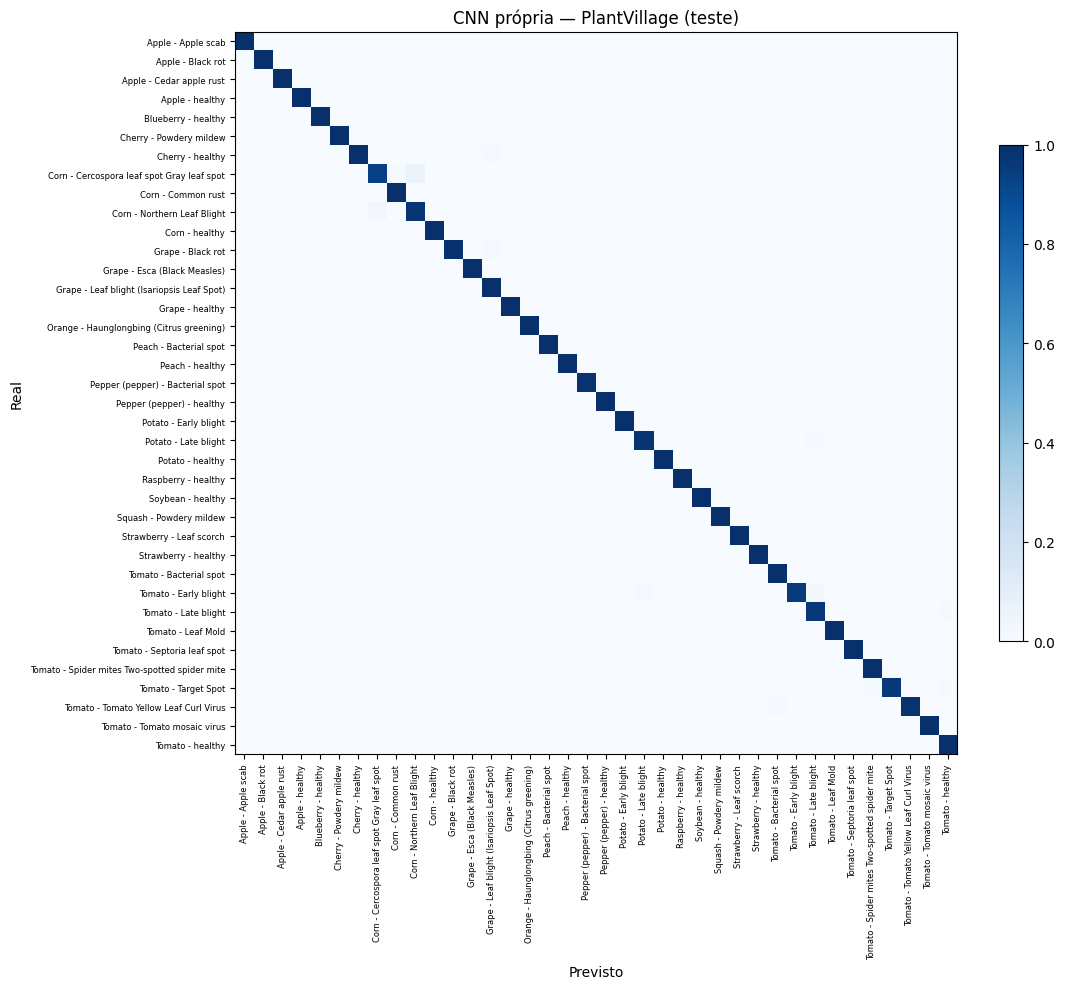

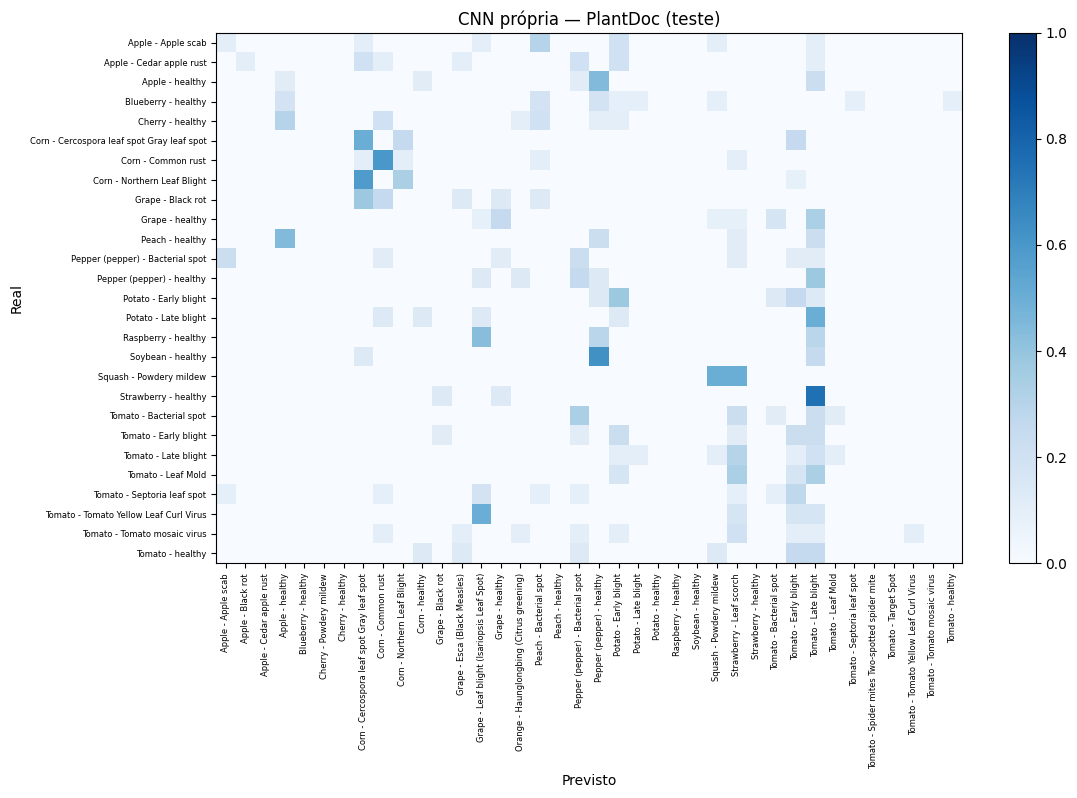

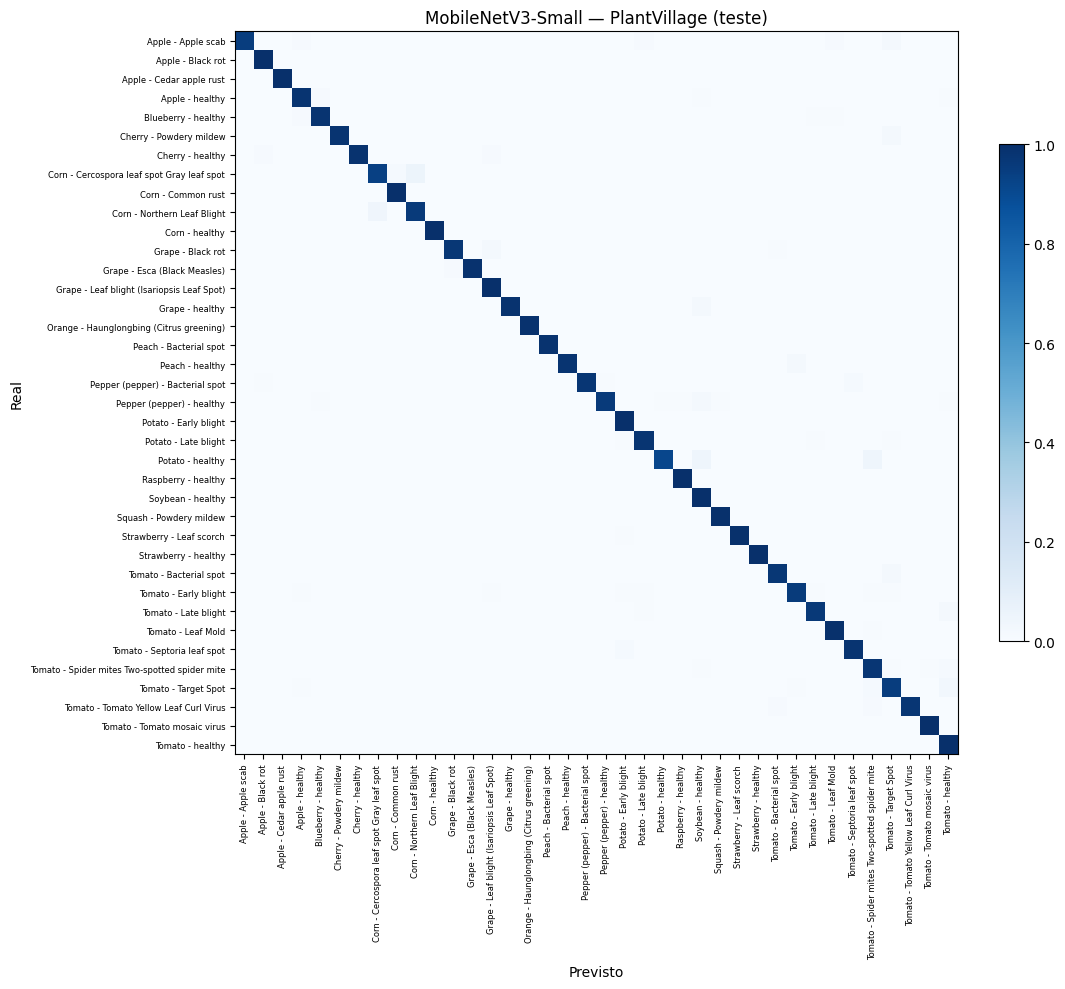

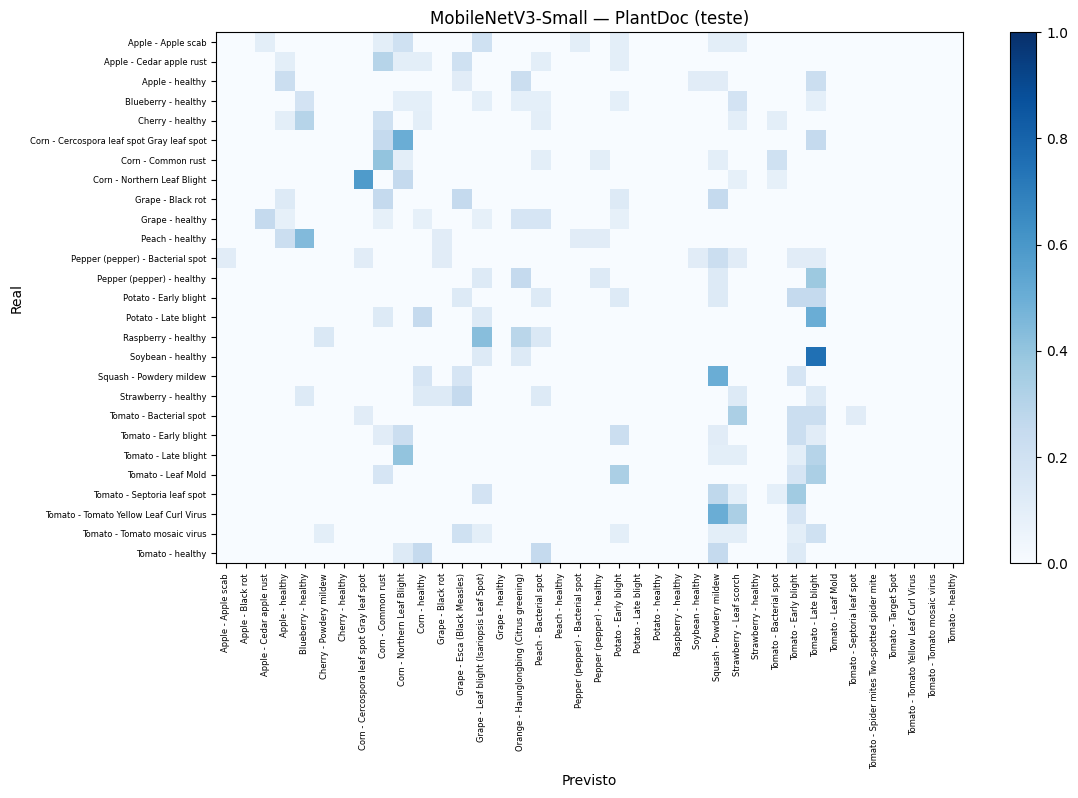

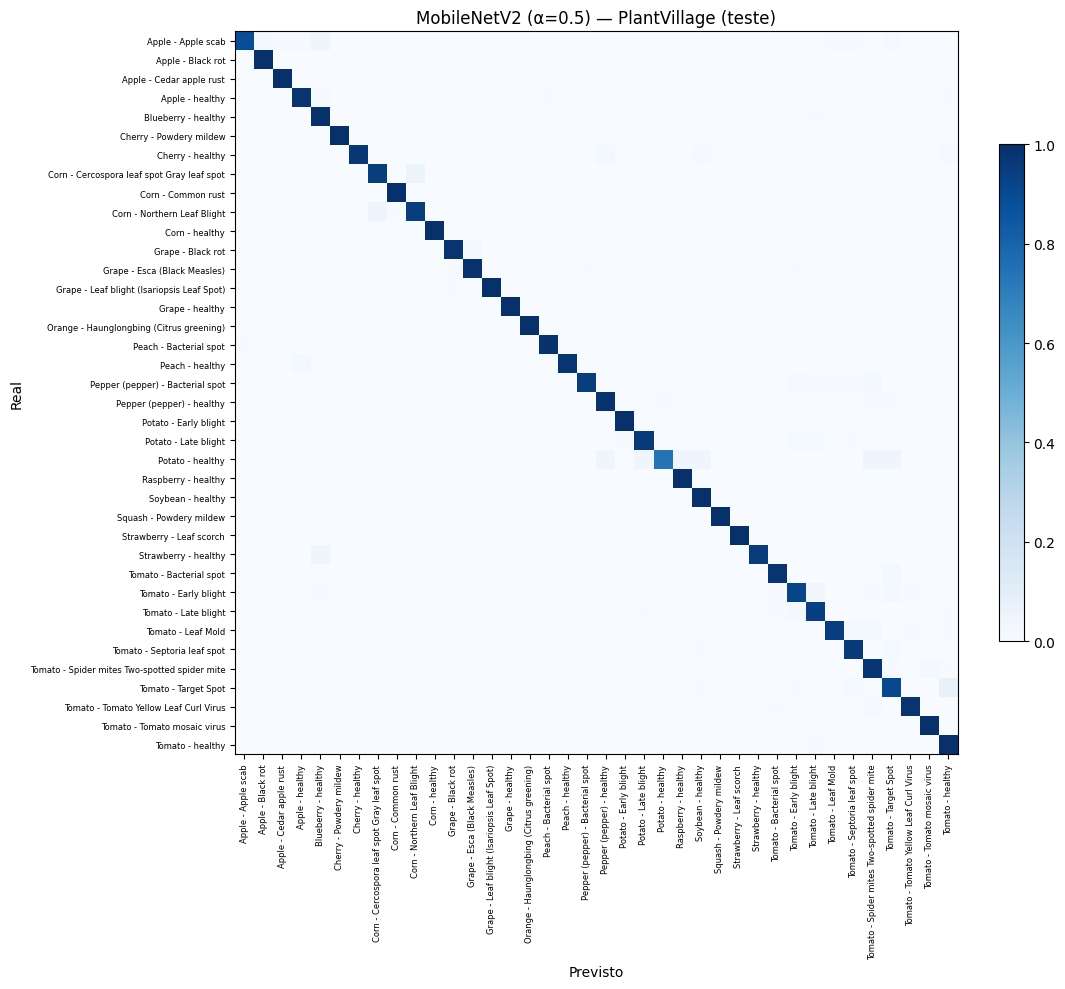

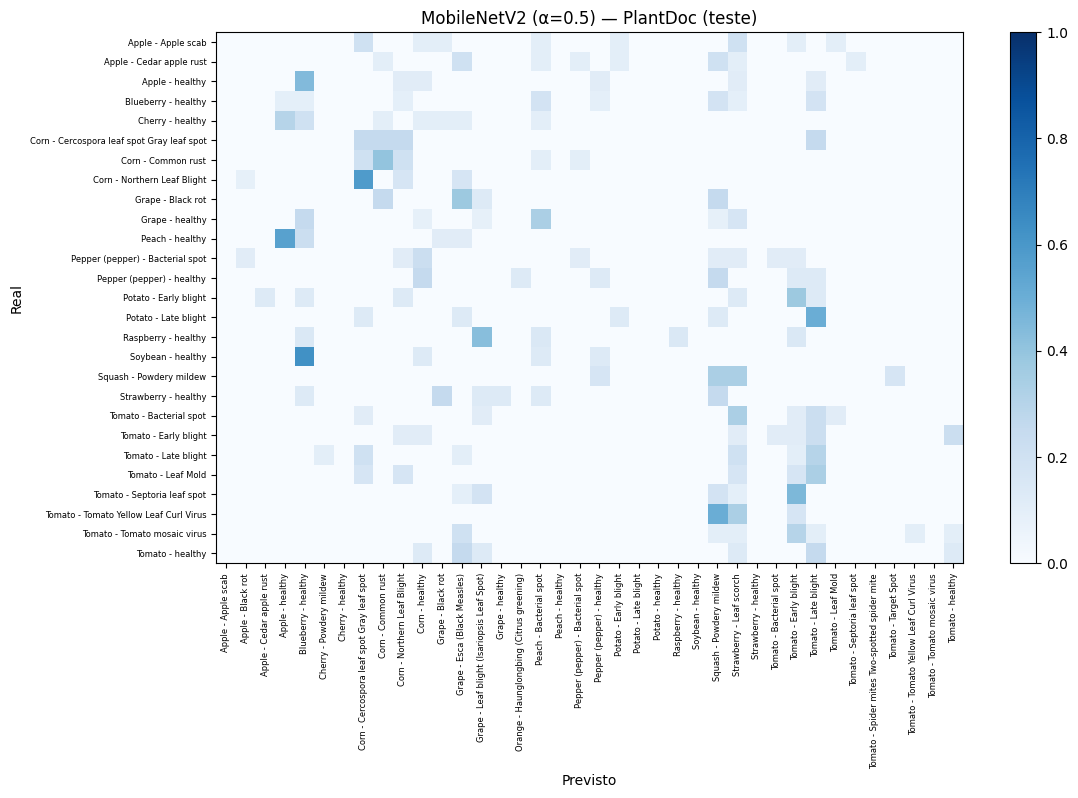

In [5]:
def plot_cm(cm, rows, cols, title, path, figsize):
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=90, fontsize=6)
    ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows, fontsize=6)
    ax.set_xlabel('Previsto'); ax.set_ylabel('Real'); ax.set_title(title)
    plt.colorbar(im, fraction=0.03)
    plt.tight_layout(); plt.savefig(path, dpi=200, bbox_inches='tight'); plt.show()

for r in RUNS:
    cm = confusion_matrix(y_te, P_PV[r].argmax(1), labels=range(len(PV_CLASSES)))
    plot_cm(cm, SHORT, SHORT, f'{NAMES[r]} — PlantVillage (teste)', f'{FIG_DIR}/cm_pv_{r}.png', (11, 10))
    cm = confusion_matrix(y_pd, P_PD[r].argmax(1), labels=range(len(PV_CLASSES)))[PD_IDX]
    plot_cm(cm, [SHORT[i] for i in PD_IDX], SHORT, f'{NAMES[r]} — PlantDoc (teste)', f'{FIG_DIR}/cm_pd_{r}.png', (12, 8))

## 6. F1 por classe no PlantDoc

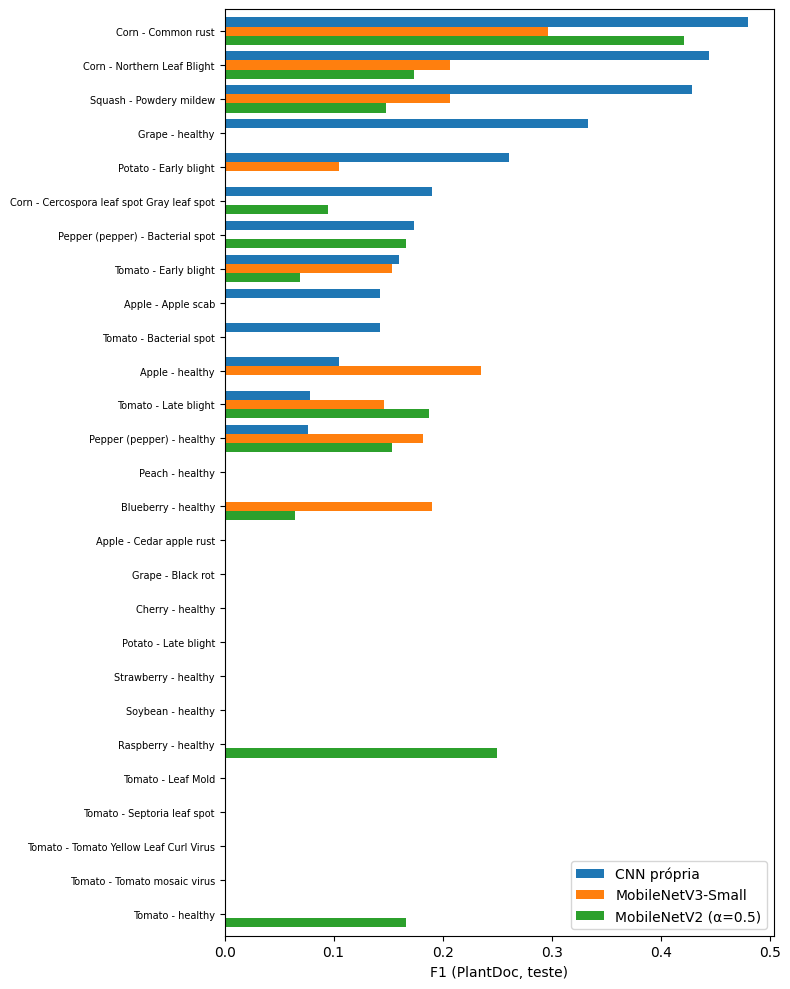

,n_teste,CNN própria,MobileNetV3-Small,MobileNetV2 (α=0.5)
Corn - Common rust,10,0.48,0.30,0.42
Corn - Northern Leaf Blight,12,0.44,0.21,0.17
Squash - Powdery mildew,6,0.43,0.21,0.15
Grape - healthy,12,0.33,0.00,0.00
Potato - Early blight,8,0.26,0.11,0.00
Corn - Cercospora leaf spot Gray leaf spot,4,0.19,0.00,0.10
Pepper (pepper) - Bacterial spot,9,0.17,0.00,0.17
Tomato - Early blight,9,0.16,0.15,0.07
Apple - Apple scab,10,0.14,0.00,0.00
Tomato - Bacterial spot,9,0.14,0.00,0.00


In [6]:
f1c = pd.DataFrame({NAMES[r]: f1_score(y_pd, P_PD[r].argmax(1), labels=PD_IDX, average=None, zero_division=0)
                    for r in RUNS}, index=[SHORT[i] for i in PD_IDX])
f1c.insert(0, 'n_teste', [int((y_pd == i).sum()) for i in PD_IDX])
f1c = f1c.sort_values(NAMES[BEST], ascending=False)
f1c.to_csv(f'{TAB_DIR}/f1_classe_pd.csv')

ax = f1c.drop(columns='n_teste').plot.barh(figsize=(8, 10), width=0.8)
ax.invert_yaxis(); ax.set_xlabel('F1 (PlantDoc, teste)'); ax.tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/f1_classe_pd.png', dpi=200, bbox_inches='tight'); plt.show()
f1c.round(2)

## 7. Confiança × acurácia (define o limiar de "foto incerta" do app)
Para cada limiar *t*, o app só responde quando a maior probabilidade ≥ *t*.
**Cobertura** = fração de fotos respondidas; **acurácia** = acerto entre as respondidas.

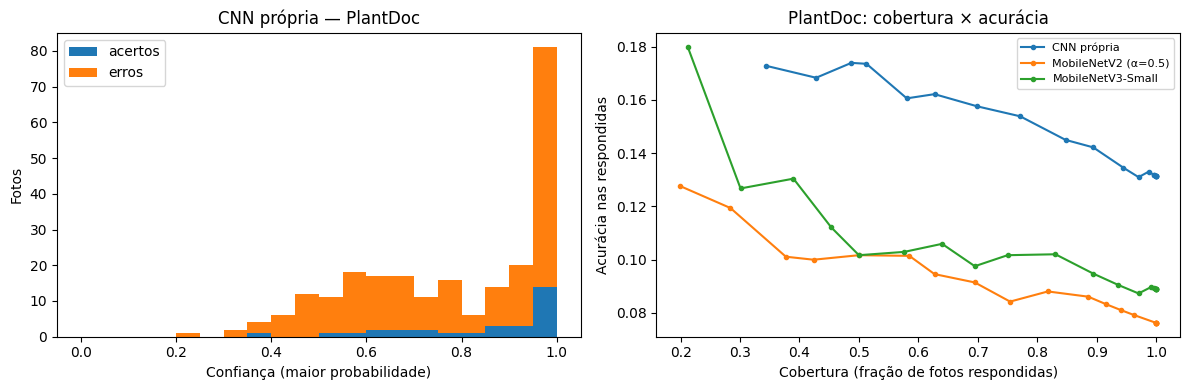

,modelo,base,limiar,cobertura,acuracia
20,CNN própria,PlantDoc,0.00,1.000,0.131
21,CNN própria,PlantDoc,0.05,1.000,0.131
22,CNN própria,PlantDoc,0.10,1.000,0.131
23,CNN própria,PlantDoc,0.15,1.000,0.131
24,CNN própria,PlantDoc,0.20,1.000,0.131
25,CNN própria,PlantDoc,0.25,0.996,0.132
26,CNN própria,PlantDoc,0.30,0.996,0.132
27,CNN própria,PlantDoc,0.35,0.987,0.133
28,CNN própria,PlantDoc,0.40,0.970,0.131
29,CNN própria,PlantDoc,0.45,0.945,0.135


In [7]:
ts = np.round(np.arange(0, 1.0, 0.05), 2)
rows = []
for r in RUNS:
    for base, y, P in (('PlantVillage', y_te, P_PV[r]), ('PlantDoc', y_pd, P_PD[r])):
        conf, pred = P.max(1), P.argmax(1)
        for t in ts:
            k = conf >= t
            rows.append({'modelo': NAMES[r], 'base': base, 'limiar': t, 'cobertura': k.mean(),
                         'acuracia': (pred[k] == y[k]).mean() if k.any() else np.nan})
lim = pd.DataFrame(rows)
lim.to_csv(f'{TAB_DIR}/limiar.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
P = P_PD[BEST]; ok = P.argmax(1) == y_pd
ax[0].hist([P.max(1)[ok], P.max(1)[~ok]], bins=20, range=(0, 1), label=['acertos', 'erros'], stacked=True)
ax[0].set(xlabel='Confiança (maior probabilidade)', ylabel='Fotos', title=f'{NAMES[BEST]} — PlantDoc')
ax[0].legend()
for (m, b), g in lim.groupby(['modelo', 'base']):
    if b == 'PlantDoc':
        ax[1].plot(g['cobertura'], g['acuracia'], marker='o', ms=3, label=m)
ax[1].set(xlabel='Cobertura (fração de fotos respondidas)', ylabel='Acurácia nas respondidas',
          title='PlantDoc: cobertura × acurácia')
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/confianca.png', dpi=200, bbox_inches='tight'); plt.show()
lim[(lim.base == 'PlantDoc') & (lim.modelo == NAMES[BEST])].round(3)

## 8. Grad-CAM
Mostra onde o modelo "olha" para decidir. Mesmas classes nas duas bases:
se no PlantDoc o mapa cai no fundo ou fora da folha, é sinal de que o modelo aprendeu atalhos do laboratório.

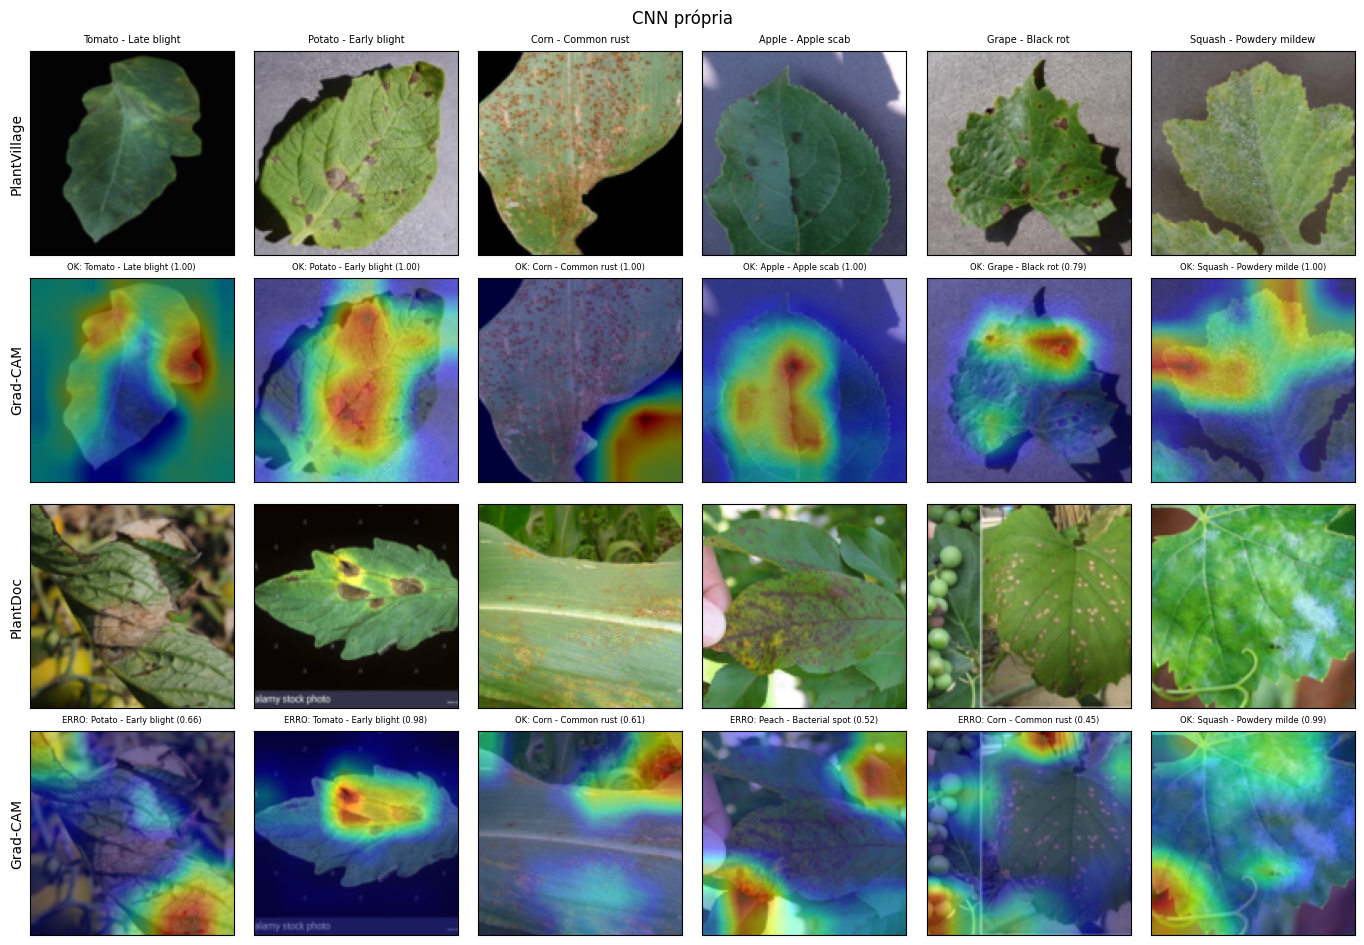

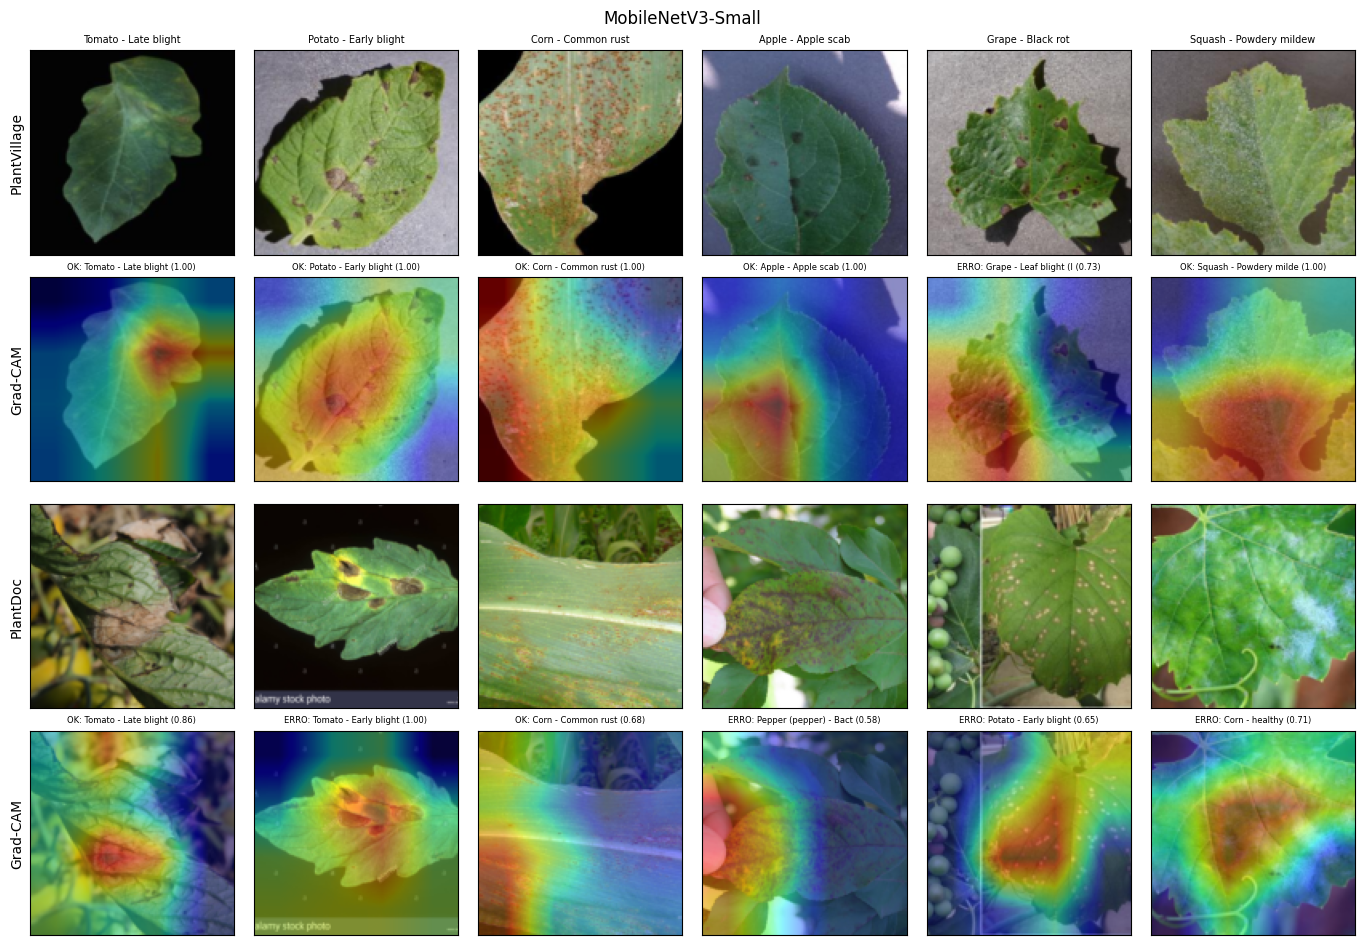

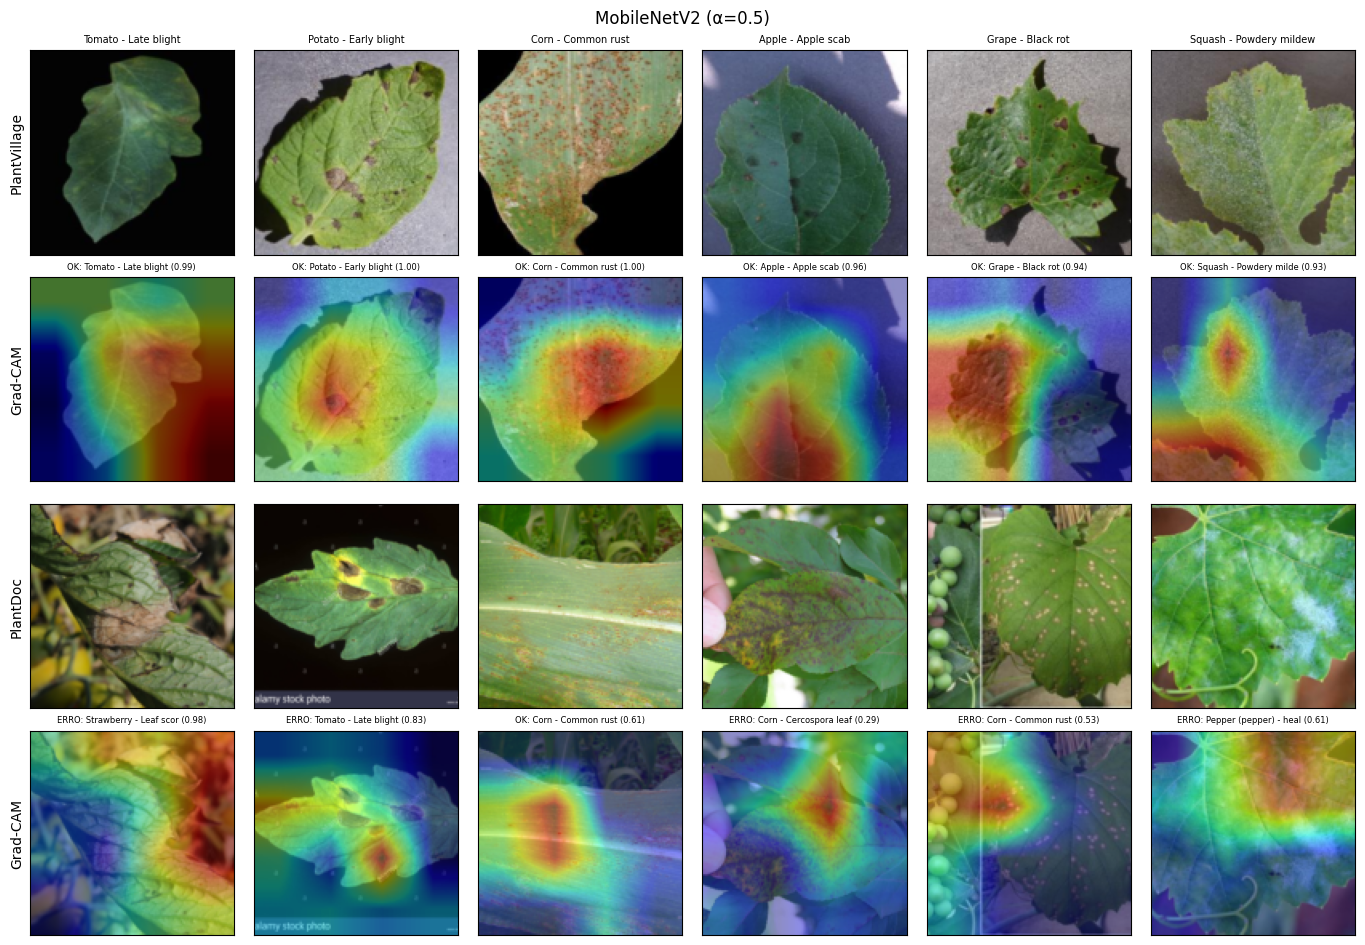

In [8]:
import tensorflow as tf
import keras

def last_4d(model):
    for l in reversed(model.layers):
        if len(l.output.shape) == 4:
            return l
    raise ValueError('nenhuma camada 4D')

class GradCAM:
    """Funciona para a CNN própria (camadas em sequência) e para as MobileNets
    (backbone aninhado como uma camada do modelo externo)."""
    def __init__(self, model):
        self.steps, self.target = [], None
        for l in model.layers[1:]:
            if isinstance(l, keras.Model):
                self.steps.append(('backbone', keras.Model(l.inputs, [last_4d(l).output, l.output])))
            else:
                self.steps.append(('layer', l))
        if not any(k == 'backbone' for k, _ in self.steps):
            self.target = last_4d(model).name   # última camada 4D antes do pooling global
    def __call__(self, img):
        x = tf.convert_to_tensor(img[None].astype('float32'))
        with tf.GradientTape() as tape:
            h, maps = x, None
            for kind, s in self.steps:
                if kind == 'backbone':
                    maps, h = s(h, training=False)
                else:
                    h = s(h, training=False)
                    if s.name == self.target:
                        maps = h
            probs = tf.cast(h, tf.float32)
            c = int(tf.argmax(probs[0]))
            score = probs[0, c]
        g = tape.gradient(score, maps)
        maps, g = tf.cast(maps, tf.float32)[0], tf.cast(g, tf.float32)[0]
        w = tf.reduce_mean(g, axis=(0, 1))
        cam = tf.nn.relu(tf.reduce_sum(maps * w, axis=-1))
        cam = cam / (tf.reduce_max(cam) + 1e-8)
        cam = tf.image.resize(cam[..., None], img.shape[:2], method='bilinear')[..., 0].numpy()
        return cam, c, float(probs[0, c])

SHOW = ['Tomato___Late_blight', 'Potato___Early_blight', 'Corn_(maize)___Common_rust_',
        'Apple___Apple_scab', 'Grape___Black_rot', 'Squash___Powdery_mildew']
rng = np.random.default_rng(SEED)
pv_x_mm = np.load(f'{CACHE_DIR}/pv_x.npy', mmap_mode='r')
pd_x = np.load(f'{CACHE_DIR}/pd_x.npy')
idx_te_global = np.where(pv_split == 2)[0]
idx_pd_global = np.where(pd_split == 2)[0]
samples = []
for c in SHOW:
    k = PV_CLASSES.index(c)
    i_pv = rng.choice(idx_te_global[y_te == k]); i_pd = rng.choice(idx_pd_global[y_pd == k])
    samples.append((c, np.array(pv_x_mm[i_pv]), pd_x[i_pd]))

def plot_gradcam(run):
    model = keras.models.load_model(f'{RUNS_DIR}/{run}/best.keras', compile=False)
    gc = GradCAM(model)
    fig, ax = plt.subplots(4, len(samples), figsize=(2.3 * len(samples), 9.6))
    for j, (c, a, b) in enumerate(samples):
        for row, img in ((0, a), (2, b)):
            cam, pred, p = gc(img)
            ok = 'OK' if pred == PV_CLASSES.index(c) else 'ERRO'
            ax[row, j].imshow(img)
            ax[row + 1, j].imshow(img); ax[row + 1, j].imshow(cam, cmap='jet', alpha=0.45)
            ax[row + 1, j].set_title(f'{ok}: {SHORT[pred][:22]} ({p:.2f})', fontsize=6)
        ax[0, j].set_title(SHORT[PV_CLASSES.index(c)], fontsize=7)
    for a in ax.ravel():
        a.set_xticks([]); a.set_yticks([])
    for row, lab in enumerate(['PlantVillage', 'Grad-CAM', 'PlantDoc', 'Grad-CAM']):
        ax[row, 0].set_ylabel(lab)
    plt.suptitle(NAMES[run]); plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/gradcam_{run}.png', dpi=200, bbox_inches='tight'); plt.show()

for r in RUNS:
    plot_gradcam(r)